In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from qss.solver_options import sa_defaults, CoolingSchedule
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot as sp
from utils.experiment_utils import run_sa_experiment

In [ ]:
MU_B  = 1 # eV/T
N = 100
t = -1
t_prim = 0.25

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 10


distros = [DistType.FD, DistType.NFLB, DistType.SSL]
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)
beta = np.array([1.0], dtype=np.float64) 
H_a = np.array([0.0], dtype=np.float64)

In [ ]:
py_opts = sa_defaults(T0=1e3,
                      T_min=1e-9,
                      alpha=0.999,
                      max_iters=50000,
                      min_iters=2000,
                      stall_iters=1000,
                      step_decay=0.999,
                      step_sigma=5.0,
                      bounds=[(-10., 10.)],
                      scale_sigma_by_T=True,
                      reflect_bounds=True,
                      sched=CoolingSchedule.Exponential
                      )
native_opts= py_opts.to_qss()

In [5]:
print("Running new experiment...")
mu_df = run_sa_experiment(
    n_vals=n,
    beta_vals=beta,
    H_a_vals=H_a,
    distros=distros,
    e_k=e_k,
    N=N,
    solver_opts=native_opts,
    logs_dir="logs",
    output_file="data/chemical_potential_results.csv"
)

mu_df


Running new experiment...
Logs will be saved to: /home/mateuszzx/Workspace/Python_Workspace/Spalek_Workspace/quantum-statistics-solver/app/BO/logs


Simulations:   0%|          | 0/30 [00:00<?, ?it/s]


Experiment finished. Aggregated results saved to: data/chemical_potential_results.csv


mu  iterations  converged      residual
distro n        k_BT H_a                                               
FD     0.010000 1.0  0.0 -6.279509        2013       True  1.720883e-06
       0.118889 1.0  0.0 -3.631827        3125       True  5.238960e-04
       0.227778 1.0  0.0 -2.801775        2014       True  6.636719e-04
       0.336667 1.0  0.0 -2.227074        3470       True  2.104381e-04
       0.445556 1.0  0.0 -1.768703        2298       True  6.393619e-05
       0.554444 1.0  0.0 -1.367191        2682       True  6.649819e-04
       0.663333 1.0  0.0 -0.990807        2000       True  5.318120e-03
       0.772222 1.0  0.0 -0.669903        2599       True  7.845433e-05
       0.881111 1.0  0.0 -0.345162        3113       True  2.257161e-04
       0.990000 1.0  0.0 -0.027883        2000       True  3.766857e-04
NFLB   0.010000 1.0  0.0 -6.935240        2000       True  5.251708e-05
       0.118889 1.0  0.0 -3.971909        2000       True  1.291231e-04
       0.227778 1.0  0.0 -2.865291        3127       True  5.053487e-04
       0.336667 1.0  0.0 -2.016923        2601       True  6.761687e-06
       0.445556 1.0  0.0 -1.258255        2000       True  3.427327e-04
       0.554444 1.0  0.0 -0.511967        2000       True  1.085992e-04
       0.663333 1.0  0.0  0.292083        3098       True  8.029418e-05
       0.772222 1.0  0.0  1.254698        2605       True  3.618427e-04
       0.881111 1.0  0.0  2.678966        2663       True  8.020348e-05
       0.990000 1.0  0.0  7.677894        2000       True  1.721283e-05
SSL    0.010000 1.0  0.0 -6.274533        2000       True  1.067328e-04
       0.118889 1.0  0.0 -3.430725        2242       True  6.803772e-05
       0.227778 1.0  0.0 -2.424616        2000       True  2.231262e-04
       0.336667 1.0  0.0 -1.669057        2000       True  8.625011e-08
       0.445556 1.0  0.0 -1.014199        2718       True  7.717817e-04
       0.554444 1.0  0.0 -0.380827        2000       True  7.202720e-04
       0.663333 1.0  0.0  0.280296        3701       True  3.881282e-04
       0.772222 1.0  0.0  1.030616        2000       True  7.792935e-04
       0.881111 1.0  0.0  2.044348        2990       True  7.512809e-05
       0.990000 1.0  0.0  4.878502        2000       True  1.297875e-05

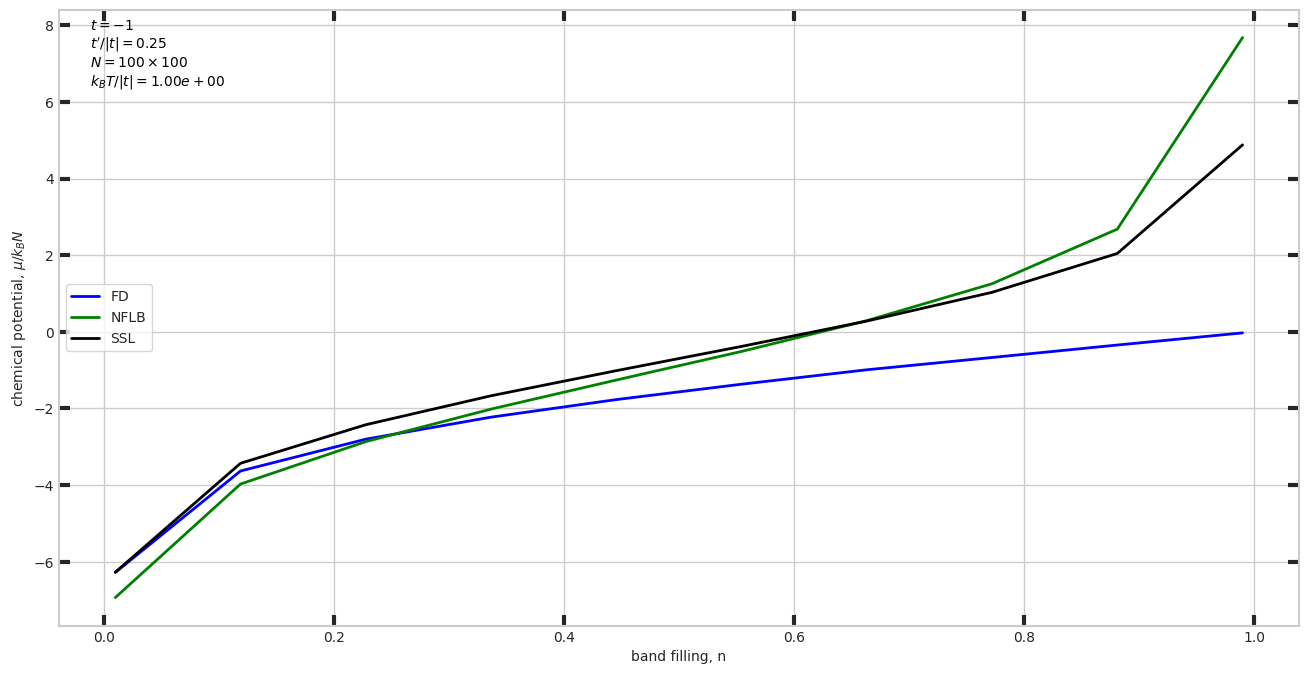

In [7]:
# Select a magnetic field to plot
H_a_plot = H_a[0]
beta_plot = beta

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=mu_df,
    n=n,
    betas=beta_plot,
    y_label=r"chemical potential, $\mu / k_B N$",
    distros=distros,
    H_a=H_a_plot,
    y_col="mu",  # Specify the column to plot
    legend_position="center left",
    figsize=(16, 8),
    cols=1 # Adjust columns for layout
)
plt.show()